# 06 - Clustering comparison (K-medoids, AGNES, DBSCAN)

The dashboard compares three clusterings on the same 682 loans and the same
standardised pre-loan behaviour features. None of them uses the default label
to fit segments; default rate is added afterwards to describe each segment.

- **K-medoids** picks real loans as centres and chooses k by silhouette.
- **AGNES (Ward)** merges loans bottom-up, minimising within-cluster variance.
- **DBSCAN** groups dense regions and marks sparse loans as noise.

The saved labels and profiles come from `scripts/build_advanced_models.py`.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

ROOT = Path("..") if Path("../data").exists() else Path(".")
SEG = ROOT / "artifacts" / "segments"

features = pd.read_csv(ROOT / "data" / "features" / "loan_features.csv")
labels = pd.read_csv(SEG / "cluster_labels.csv")
profiles = pd.read_csv(SEG / "cluster_profiles.csv")

DROP = ["loan_id", "account_id", "loan_date_id", "client_id", "district_id",
        "status", "date", "parsed_date", "gender", "target"]
features.shape, labels.shape


((682, 27), (682, 4))

## Segment profiles

Size and default rate are descriptive; they did not guide the clustering.


In [2]:
names = {"kmedoids": "K-medoids", "agnes": "AGNES (Ward)", "dbscan": "DBSCAN"}
view = profiles.copy()
view["method"] = view["method"].map(names)
view["segment"] = view["cluster"].map(lambda value: "noise" if value == -1 else str(value))
view["default %"] = (view["default_rate"] * 100).round(1)
view[["method", "segment", "size", "default %", "avg_amount", "avg_balance", "avg_age", "avg_n_txn"]].round(1)


,method,segment,size,default %,avg_amount,avg_balance,avg_age,avg_n_txn
0,K-medoids,0,219,10.5,166200.3,55627.9,39.4,108.0
1,K-medoids,1,288,9.4,139284.6,34276.0,41.4,90.3
2,K-medoids,2,175,14.9,152856.5,43919.0,41.9,28.9
3,AGNES (Ward),0,365,10.4,123157.2,34888.1,41.5,73.0
4,AGNES (Ward),1,317,12.0,183941.2,53645.7,40.2,88.4
5,DBSCAN,noise,135,21.5,200290.7,50186.2,40.8,104.4
6,DBSCAN,0,542,8.7,139944.9,41785.5,41.0,73.4
7,DBSCAN,1,5,0.0,74476.8,63394.1,32.8,163.6


## Default rate by segment

The dashed line is the portfolio base rate. Red bars sit above it.


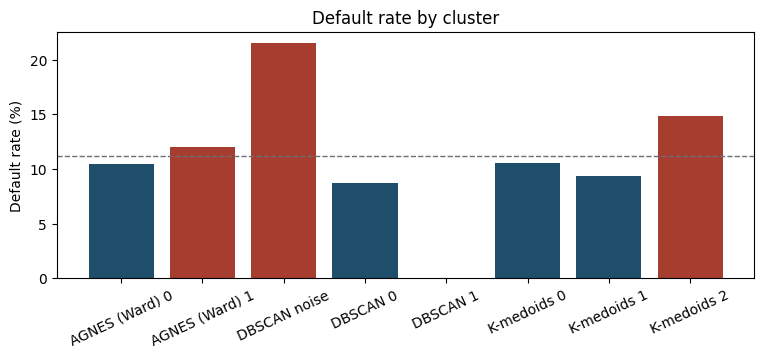

In [3]:
base = features["target"].mean()
frame = profiles.sort_values(["method", "cluster"]).reset_index(drop=True)
x_labels = [f"{names[row.method]} {'noise' if row.cluster == -1 else row.cluster}" for row in frame.itertuples()]
rates = frame["default_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(x_labels, rates, color=["#a63d2f" if rate > base * 100 else "#1f4e6b" for rate in rates])
ax.axhline(base * 100, color="#6b6f76", linestyle="--", linewidth=1)
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by cluster")
ax.tick_params(axis="x", rotation=25)
plt.show()


## Cluster map

PCA compresses the feature space to two axes so the segments can be seen.
Nearby points behave similarly; distances are approximate.


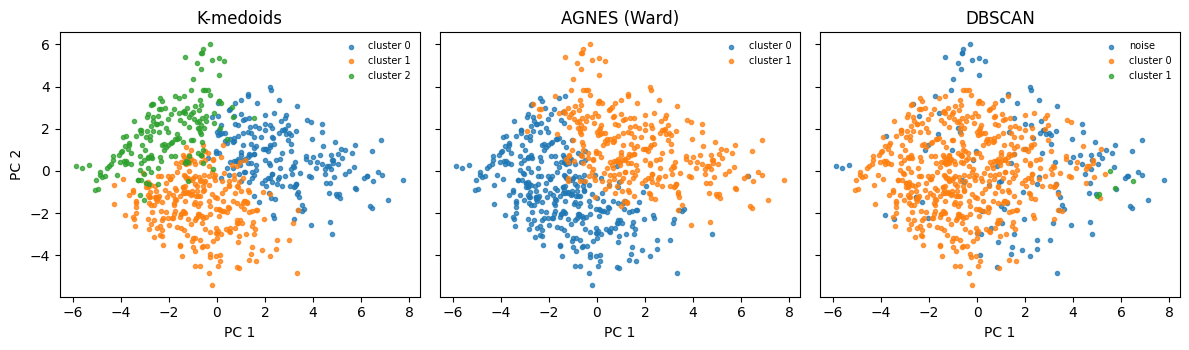

In [4]:
matrix = StandardScaler().fit_transform(features.drop(columns=[column for column in DROP if column in features]))
points = PCA(n_components=2, random_state=42).fit_transform(matrix)
joined = labels.set_index("loan_id").reindex(features["loan_id"])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for ax, (key, title) in zip(axes, [("kmedoids", "K-medoids"), ("agnes", "AGNES (Ward)"), ("dbscan", "DBSCAN")]):
    values = joined[key].to_numpy()
    for cluster in sorted(set(values)):
        mask = values == cluster
        ax.scatter(points[mask, 0], points[mask, 1], s=9, alpha=0.75,
                   label="noise" if cluster == -1 else f"cluster {cluster}")
    ax.set_title(title)
    ax.set_xlabel("PC 1")
    ax.legend(fontsize=7, frameon=False)
axes[0].set_ylabel("PC 2")
plt.tight_layout()
plt.show()


In [5]:
assert len(features) == len(labels) == 682
assert labels[["kmedoids", "agnes", "dbscan"]].notna().all().all()
assert profiles.groupby("method")["size"].sum().eq(len(features)).all()

noise = profiles.query("method == 'dbscan' and cluster == -1")["default_rate"].iloc[0]
assert noise > base
print(f"checks passed; DBSCAN noise default rate {noise:.1%} vs {base:.1%} base")


checks passed; DBSCAN noise default rate 21.5% vs 11.1% base


## What the graphs say

- DBSCAN noise: 135 loans with a 21.5% default rate, almost twice the 11.1% base rate.
- K-medoids segment 2: 175 loans at 14.9%, the highest of its three bands.
- AGNES splits the book into two broad bands at 10.4% and 12.0%.
- The clusters overlap on the map, so treat them as behaviour bands rather than hard risk classes.
